# 🔬 Experiment Explorer
Carga todos los experimentos de `RESULTS_PATH`, agrupa por **tarea → encoder × freeze × MIL**, y ordena por la métrica elegida. Al final de cada tarea aparece un barplot comparando todas las combinaciones.

In [52]:
# ─────────────────────────────────────────────
# CONFIGURACIÓN  ← edita aquí
# ─────────────────────────────────────────────
RESULTS_PATH  = '/workspace/results'  # carpeta raíz con todos los experimentos
RANK_METRIC   = 'balanced_accuracy'            # métrica de ranking: 'auroc', 'f1_macro', 'balanced_accuracy', 'mcc', ...
RANK_SPLIT    = 'test'             # 'val' → mejor época val  |  'test' → resultado en test
TOP_N         = 3                  # filas por subgrupo (tarea × encoder × freeze × mil)
TOP_N_GLOBAL  = 10                 # filas en el ranking global final
TASK_FILTER   = None               # None → todas | p.ej. 'er', 'molecular_subtype', ...
ASCENDING     = False              # False → mayor es mejor (AUC, F1) | True → menor es mejor

In [53]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display, HTML

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 60)
pd.set_option('display.float_format', '{:.4f}'.format)

In [54]:
# ─────────────────────────────────────────────────────────────────────────────
# PARSER del nombre de carpeta
# Formato: [nickname_]YYYYMMDD_HHMMSS_task-TASK[_ductal][_weighted_loss]
#          _model-MODEL_frozen|unfrozen_MIL-MILMODE_OPT_lrLR_wdWD_bsBS_epEP[_small]
# ─────────────────────────────────────────────────────────────────────────────
RUN_RE = re.compile(
    r'''
    (?:(?P<nickname>.+?)_)?          # nickname opcional
    (?P<timestamp>\d{8}_\d{6})_     # timestamp
    task-(?P<task>[^_]+)             # task
    (?P<ductal>_ductal)?             # flag ductal
    (?P<weighted>_weighted_loss)?    # flag weighted loss
    _model-(?P<model>[^_]+)_         # patch model
    (?P<freeze>frozen|unfrozen)_     # frozen / unfrozen
    MIL-(?P<mil>[^_]+)_             # MIL mode
    (?P<optimizer>AdamW|SGD[^_]*)_  # optimizer
    lr(?P<lr>[\d.e+-]+)_            # learning rate
    wd(?P<wd>[\d.e+-]+)_            # weight decay
    bs(?P<bs>\d+)_                  # batch size
    ep(?P<ep>\d+)                    # epochs
    (?P<small>_small)?               # flag small
    ''', re.VERBOSE)

def parse_run_name(folder):
    m = RUN_RE.search(folder)
    if m is None:
        return None
    d = m.groupdict()
    return dict(
        run_name=folder, nickname=d['nickname'] or '',
        timestamp=d['timestamp'], task=d['task'],
        model=d['model'], freeze=d['freeze'], mil=d['mil'],
        optimizer=d['optimizer'],
        lr=float(d['lr']), wd=float(d['wd']),
        batch_size=int(d['bs']), epochs=int(d['ep']),
        ductal=d['ductal'] is not None,
        weighted_loss=d['weighted'] is not None,
        small=d['small'] is not None,
    )

print('Parser cargado ✓')

Parser cargado ✓


In [64]:
# ─────────────────────────────────────────────────────────────────────────────
# CARGA DE MÉTRICAS Y CONSTRUCCIÓN DEL DATAFRAME MAESTRO
# ─────────────────────────────────────────────────────────────────────────────
METRIC_COLS = [
    'accuracy', 'balanced_accuracy',
    'f1_macro', 'f1_weighted',
    'auroc', 'auroc_macro', 'auroc_weighted',
    'auprc_macro', 'auprc_weighted',
    'mcc', 'kappa',
]

def load_csv(run_dir, split):
    p = os.path.join(run_dir, f'{split}_metrics.csv')
    if not os.path.isfile(p):
        return None
    df = pd.read_csv(p)
    return df.drop(columns=['classification_report'], errors='ignore')

def best_val_row(val_df, metric, ascending):
    if val_df is None or metric not in val_df.columns:
        return None
    idx = val_df[metric].agg('idxmin' if ascending else 'idxmax')
    return val_df.loc[idx]

def collect_all_runs(results_path, rank_metric, rank_split, ascending, task_filter):
    records, skipped = [], 0
    candidates = sorted(os.listdir(results_path))
    print(f'Carpetas encontradas: {len(candidates)}')

    for folder in candidates:
        run_dir = os.path.join(results_path, folder)
        if not os.path.isdir(run_dir):
            continue
        meta = parse_run_name(folder)
        if meta is None:
            skipped += 1; continue
        if task_filter and meta['task'] != task_filter:
            continue

        if rank_split == 'test':
            sdf = load_csv(run_dir, 'test')
            if sdf is None or sdf.empty:
                skipped += 1; continue
            row = sdf.iloc[0]
        else:
            vdf = load_csv(run_dir, 'val')
            row = best_val_row(vdf, rank_metric, ascending)
            if row is None:
                skipped += 1; continue

        if rank_metric not in row.index or pd.isna(row[rank_metric]):
            skipped += 1; continue

        record = {**meta, 'rank_value': row[rank_metric]}
        for col in METRIC_COLS:
            if col in row.index:
                record[col] = row[col]
        if rank_split == 'val' and 'epoch' in row.index:
            record['best_epoch'] = int(row['epoch'])
        records.append(record)

    print(f'Cargados: {len(records)}  |  Omitidos/incompletos: {skipped}')
    if not records:
        return pd.DataFrame()
    df = pd.DataFrame(records)
    return df.sort_values('rank_value', ascending=ascending).reset_index(drop=True)


all_runs = collect_all_runs(RESULTS_PATH, RANK_METRIC, RANK_SPLIT, ASCENDING, TASK_FILTER)
print(f'\nTotal válidos: {len(all_runs)}')
if not all_runs.empty:
    print(f'Tareas:  {sorted(all_runs["task"].unique())}')
    print(f'Modelos: {sorted(all_runs["model"].unique())}')
    print(f'MIL:     {sorted(all_runs["mil"].unique())}')

Carpetas encontradas: 81
Cargados: 78  |  Omitidos/incompletos: 1

Total válidos: 78
Tareas:  ['er', 'pr']
Modelos: ['dino', 'uni']
MIL:     ['abMIL-bag-level', 'abMIL-instance-level', 'transMIL']


In [56]:
# ─────────────────────────────────────────────────────────────────────────────
# HELPERS DE VISUALIZACIÓN
# ─────────────────────────────────────────────────────────────────────────────
DISPLAY_METRICS = ['rank_value'] + METRIC_COLS
META_COLS = ['freeze', 'lr', 'wd', 'batch_size', 'optimizer', 'weighted_loss', 'ductal']


def show_group_table(group_df, group_label, top_n):
    top = group_df.head(top_n).copy()
    top.index = range(1, len(top) + 1)
    extra = [c for c in ['best_epoch'] if c in top.columns]
    metric_cols = [c for c in DISPLAY_METRICS if c in top.columns]
    cols = [c for c in META_COLS + extra + metric_cols if c in top.columns]
    top = top[cols].rename(columns={'rank_value': f'► {RANK_METRIC} ({RANK_SPLIT})'})
    display(HTML(f"<h4 style='margin-top:16px; margin-bottom:2px'>{group_label}</h4>"))
    display(top.style.format(precision=4, na_rep='—'))


def barplot_task(task_df, task):
    # Métricas a graficar: RANK_METRIC primero, luego el resto de DISPLAY_METRICS que existan
    candidates   = [RANK_METRIC] + [m for m in DISPLAY_METRICS if m != 'rank_value' and m != RANK_METRIC]
    plot_metrics = [m for m in candidates if m in task_df.columns and task_df[m].notna().any()]

    if not plot_metrics:
        print(f'Sin métricas disponibles para {task}')
        return

    models = sorted(task_df['model'].unique())
    mils   = sorted(task_df['mil'].unique())
    mil_cmap  = plt.get_cmap('tab10')
    mil_color = {m: mil_cmap(i) for i, m in enumerate(mils)}

    bar_w       = 0.8 / max(len(mils), 1)
    encoder_gap = 0.5

    def make_fig(metric):
        agg = (
            task_df
            .groupby(['model', 'mil'])[metric]
            .agg('min' if ASCENDING else 'max')
            .reset_index()
        )
        positions, group_centers, sep_lines = [], {}, []
        x = 0.0
        for ei, model in enumerate(models):
            block_start = x
            for mi, mil in enumerate(mils):
                row = agg[(agg['model'] == model) & (agg['mil'] == mil)]
                if row.empty:
                    continue
                positions.append((x + mi * bar_w + bar_w / 2,
                                  float(row[metric].iloc[0]), mil, model))
            block_end = x + len(mils) * bar_w
            group_centers[model] = (block_start + block_end) / 2
            if ei < len(models) - 1:
                sep_lines.append(block_end + encoder_gap / 2)
            x = block_end + encoder_gap
        total_width = x - encoder_gap

        fig, ax = plt.subplots(figsize=(max(5, total_width * 1.4), 4.8))
        for (bx, val, mil, model) in positions:
            ax.bar(bx, val, width=bar_w * 0.88,
                   color=mil_color[mil], edgecolor='white', linewidth=0.5, zorder=2)
            ax.text(bx, val + 0.003, f'{val:.3f}',
                    ha='center', va='bottom', fontsize=7.5)
        for xsep in sep_lines:
            ax.axvline(xsep, color='#aaaaaa', linewidth=1.0, linestyle='--', zorder=1)
        ax.set_xticks(list(group_centers.values()))
        ax.set_xticklabels(list(group_centers.keys()), fontsize=10, fontweight='bold')
        ax.tick_params(axis='x', length=0)
        ax.set_ylabel(f'{metric} ({RANK_SPLIT})', fontsize=8)
        ax.set_title(f'{task}  —  {metric}', fontsize=9)
        ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.3f'))
        ax.grid(axis='y', alpha=0.3, zorder=1)
        ax.spines[['top', 'right']].set_visible(False)
        ax.set_xlim(-0.4, total_width + 0.4)
        mil_handles = [plt.Rectangle((0,0),1,1, color=mil_color[m], label=m) for m in mils]
        ax.legend(handles=mil_handles, title='MIL', fontsize=8, title_fontsize=8, loc='lower right')
        plt.tight_layout()
        return fig

    # Generar figuras independientes y mostrarlas de 3 en 3 en filas HTML
    from IPython.display import display, HTML
    import io, base64

    def fig_to_b64(fig):
        buf = io.BytesIO()
        fig.savefig(buf, format='png', dpi=120, bbox_inches='tight')
        plt.close(fig)
        buf.seek(0)
        return base64.b64encode(buf.read()).decode()

    GROUP = 3
    for start in range(0, len(plot_metrics), GROUP):
        chunk = plot_metrics[start:start + GROUP]
        imgs_html = ''
        for metric in chunk:
            fig = make_fig(metric)
            b64 = fig_to_b64(fig)
            imgs_html += (
                f'<a href="data:image/png;base64,{b64}" download="{task}_{metric}.png" '
                f'title="Descargar {metric}">'
                f'<img src="data:image/png;base64,{b64}" '
                f'style="height:340px; margin:4px; border:1px solid #ddd; '
                f'border-radius:4px; cursor:pointer;" /></a>'
            )
        display(HTML(
            f'<div style="display:flex; flex-wrap:nowrap; overflow-x:auto; '
            f'gap:6px; padding:4px 0;">{imgs_html}</div>'
        ))


print('Helpers cargados ✓')


Helpers cargados ✓


,freeze,lr,wd,batch_size,optimizer,weighted_loss,ductal,► balanced_accuracy (test),accuracy,balanced_accuracy,f1_macro,f1_weighted,auroc,auprc_macro,auprc_weighted,mcc,kappa
1,frozen,0.0000,0.0010,32,AdamW,True,False,0.6874,0.7020,0.6874,0.6545,0.7181,0.7275,0.6485,0.7709,0.3354,0.3214
2,frozen,0.0000,0.0005,32,AdamW,True,False,0.6874,0.7020,0.6874,0.6545,0.7181,0.7275,0.6485,0.7709,0.3354,0.3214
3,frozen,0.0000,0.0001,32,AdamW,True,False,0.6874,0.7020,0.6874,0.6545,0.7181,0.7275,0.6485,0.7709,0.3354,0.3214


,freeze,lr,wd,batch_size,optimizer,weighted_loss,ductal,► balanced_accuracy (test),accuracy,balanced_accuracy,f1_macro,f1_weighted,auroc,auprc_macro,auprc_weighted,mcc,kappa
1,frozen,0.0000,0.0010,32,AdamW,True,False,0.6566,0.6821,0.6566,0.6293,0.6988,0.6810,0.6220,0.7347,0.2814,0.2707
2,frozen,0.0000,0.0001,32,AdamW,True,False,0.6566,0.6821,0.6566,0.6293,0.6988,0.6810,0.6220,0.7347,0.2814,0.2707
3,frozen,0.0000,0.0005,32,AdamW,True,False,0.6566,0.6821,0.6566,0.6293,0.6988,0.6810,0.6220,0.7347,0.2814,0.2707


,freeze,lr,wd,batch_size,optimizer,weighted_loss,ductal,► balanced_accuracy (test),accuracy,balanced_accuracy,f1_macro,f1_weighted,auroc,auprc_macro,auprc_weighted,mcc,kappa
1,frozen,0.0000,0.0005,32,AdamW,True,False,0.6787,0.7152,0.6787,0.6575,0.7273,0.7711,0.7119,0.8136,0.3280,0.3210
2,frozen,0.0000,0.0010,32,AdamW,True,False,0.6787,0.7152,0.6787,0.6575,0.7273,0.7711,0.7119,0.8136,0.3280,0.3210
3,frozen,0.0000,0.0001,32,AdamW,True,False,0.6787,0.7152,0.6787,0.6575,0.7273,0.7711,0.7119,0.8136,0.3280,0.3210


,freeze,lr,wd,batch_size,optimizer,weighted_loss,ductal,► balanced_accuracy (test),accuracy,balanced_accuracy,f1_macro,f1_weighted,auroc,auprc_macro,auprc_weighted,mcc,kappa
1,frozen,0.0000,0.0001,32,AdamW,True,False,0.7930,0.7947,0.7930,0.7562,0.8043,0.8661,0.8375,0.8929,0.5328,0.5181
2,frozen,0.0000,0.0005,32,AdamW,True,False,0.7930,0.7947,0.7930,0.7562,0.8043,0.8661,0.8375,0.8929,0.5328,0.5181
3,frozen,0.0000,0.0001,32,AdamW,True,False,0.7930,0.7947,0.7930,0.7562,0.8043,0.8638,0.8375,0.8919,0.5328,0.5181


,freeze,lr,wd,batch_size,optimizer,weighted_loss,ductal,► balanced_accuracy (test),accuracy,balanced_accuracy,f1_macro,f1_weighted,auroc,auprc_macro,auprc_weighted,mcc,kappa
1,frozen,0.0000,0.0005,32,AdamW,True,False,0.7318,0.7947,0.7318,0.7298,0.7956,0.7925,0.7593,0.8309,0.4597,0.4597
2,frozen,0.0000,0.0001,32,AdamW,True,False,0.7318,0.7947,0.7318,0.7298,0.7956,0.7925,0.7593,0.8309,0.4597,0.4597
3,frozen,0.0000,0.0010,32,AdamW,True,False,0.7318,0.7947,0.7318,0.7298,0.7956,0.7925,0.7593,0.8309,0.4597,0.4597


,freeze,lr,wd,batch_size,optimizer,weighted_loss,ductal,► balanced_accuracy (test),accuracy,balanced_accuracy,f1_macro,f1_weighted,auroc,auprc_macro,auprc_weighted,mcc,kappa
1,frozen,0.0000,0.0005,32,AdamW,True,False,0.7845,0.8212,0.7845,0.7722,0.8247,0.8763,0.8440,0.8983,0.5471,0.5451
2,frozen,0.0000,0.0001,32,AdamW,True,False,0.7845,0.8212,0.7845,0.7722,0.8247,0.8763,0.8440,0.8983,0.5471,0.5451
3,frozen,0.0000,0.0010,32,AdamW,True,False,0.7845,0.8212,0.7845,0.7722,0.8247,0.8763,0.8440,0.8983,0.5471,0.5451



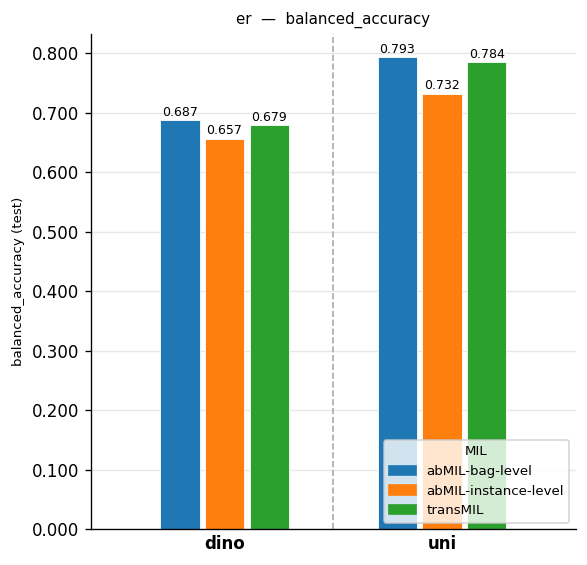
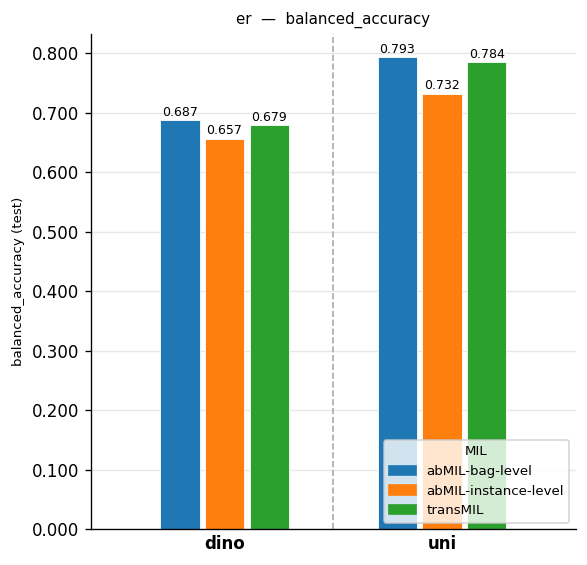
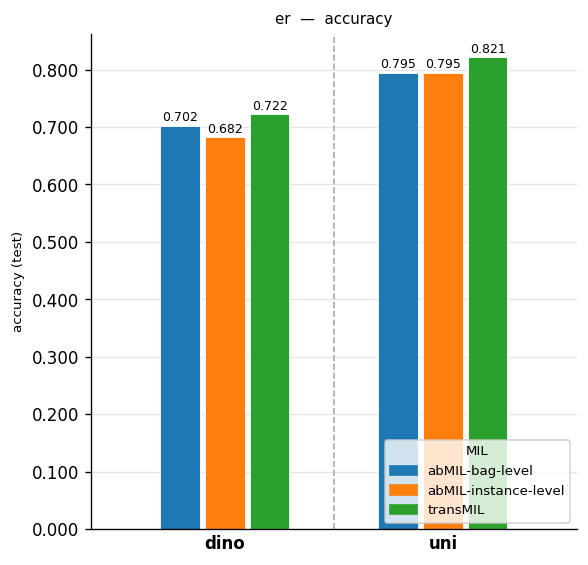
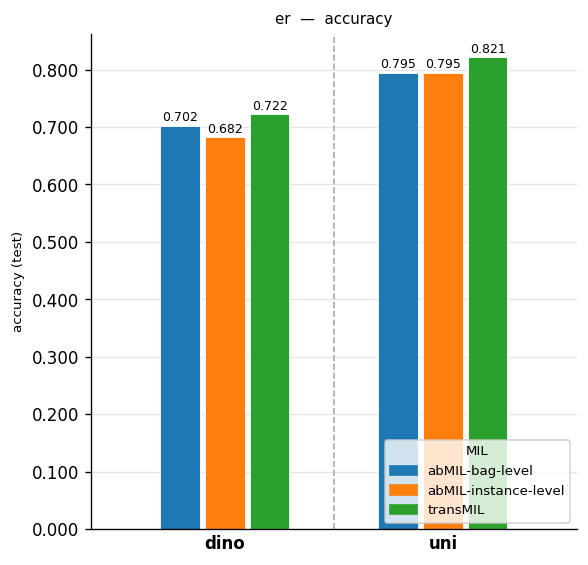
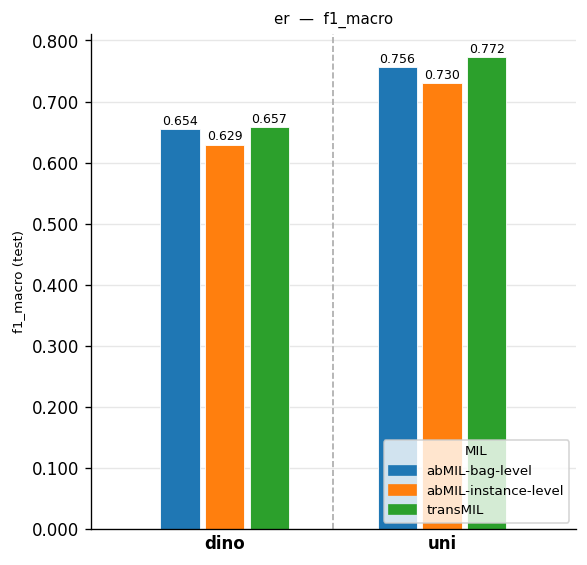
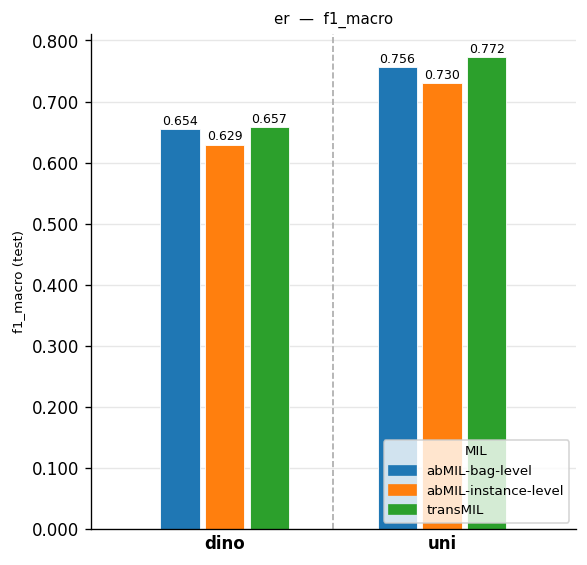


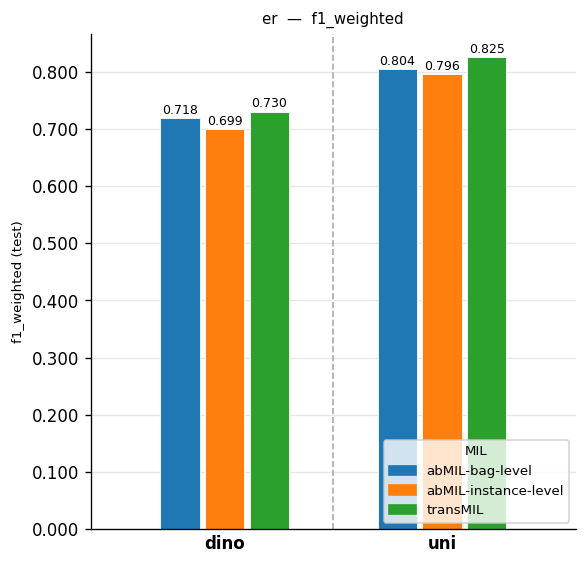
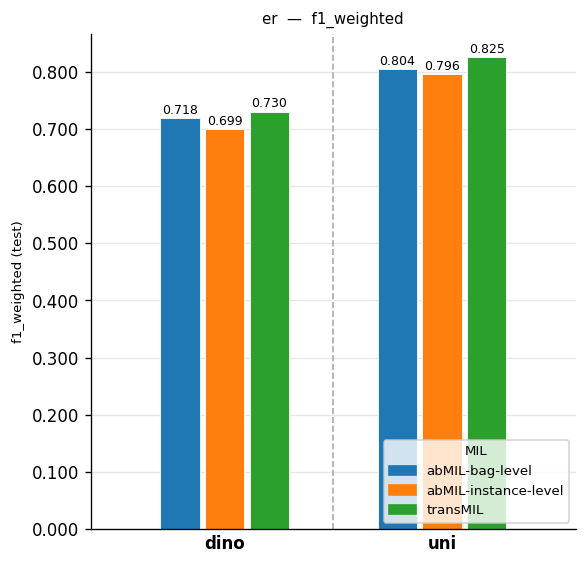
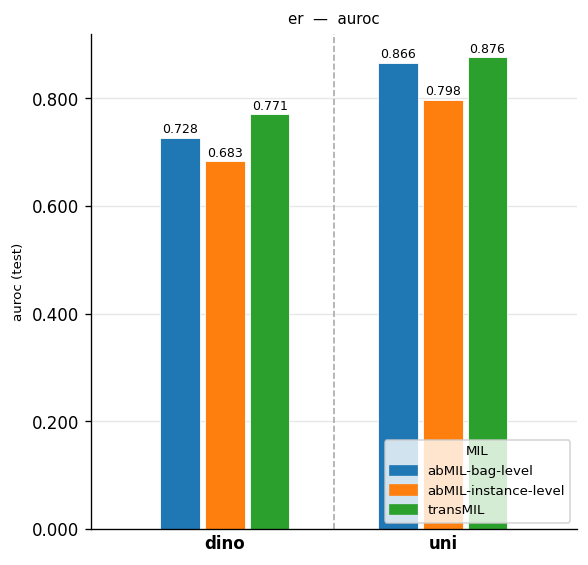
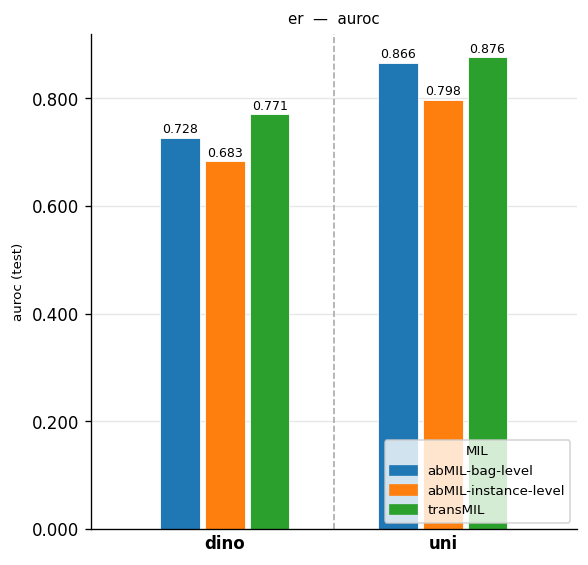
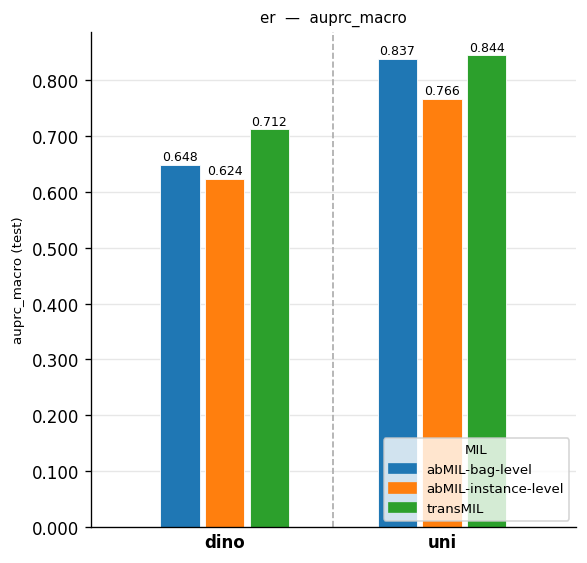
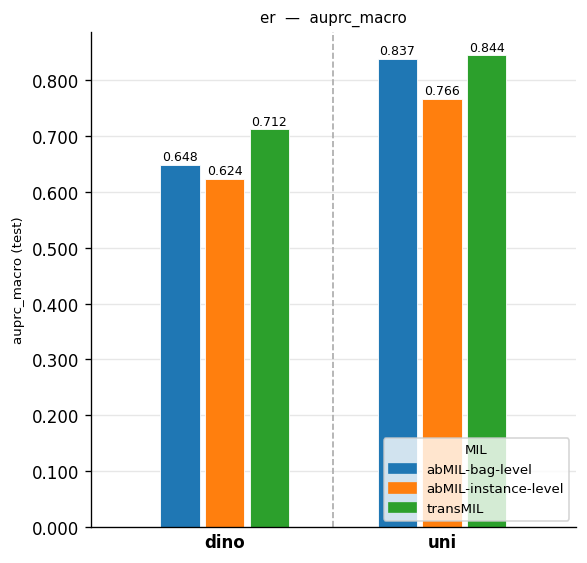


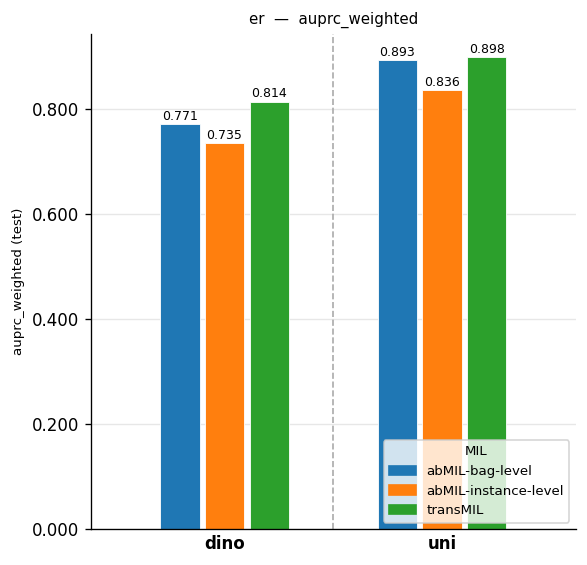
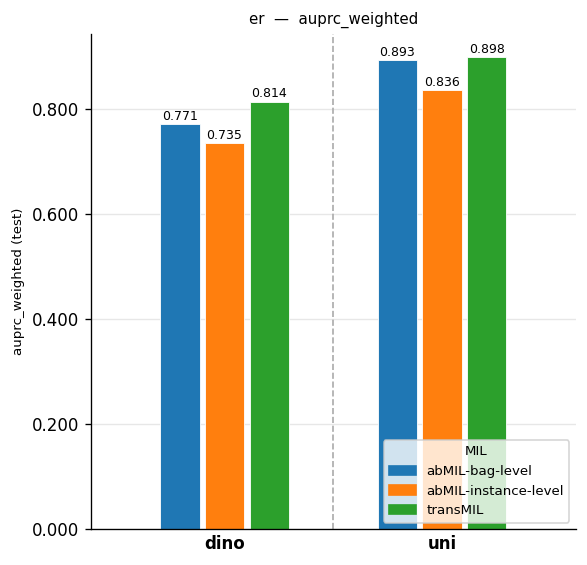
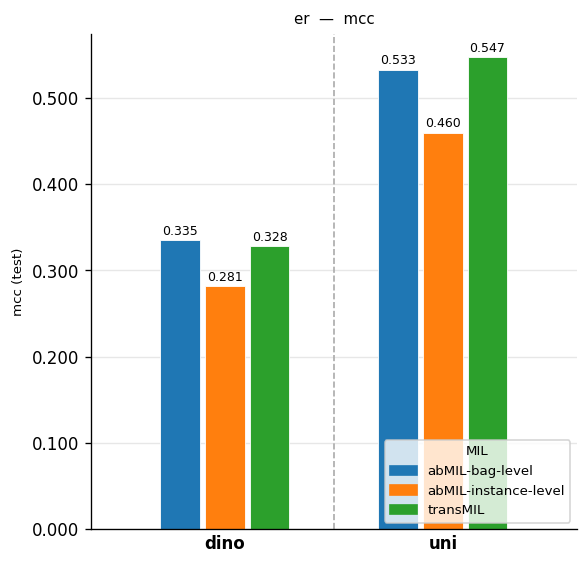
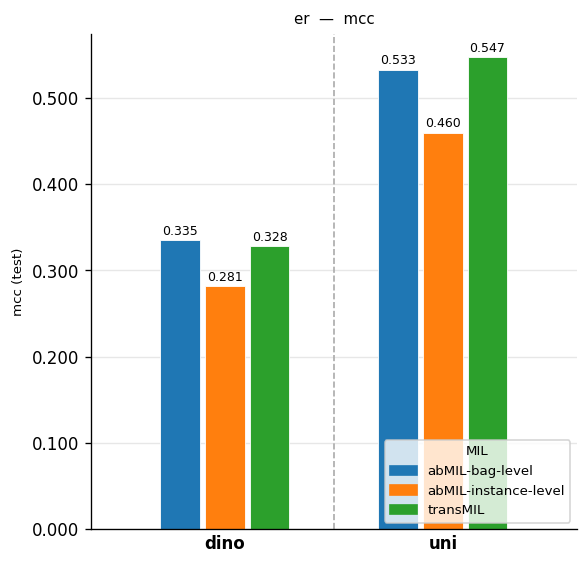
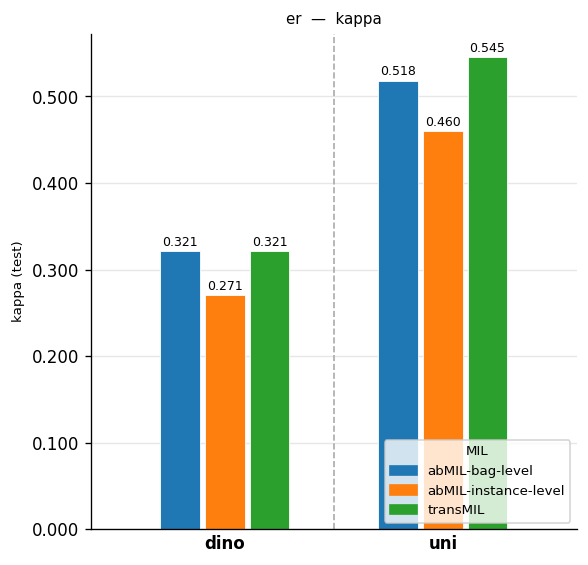
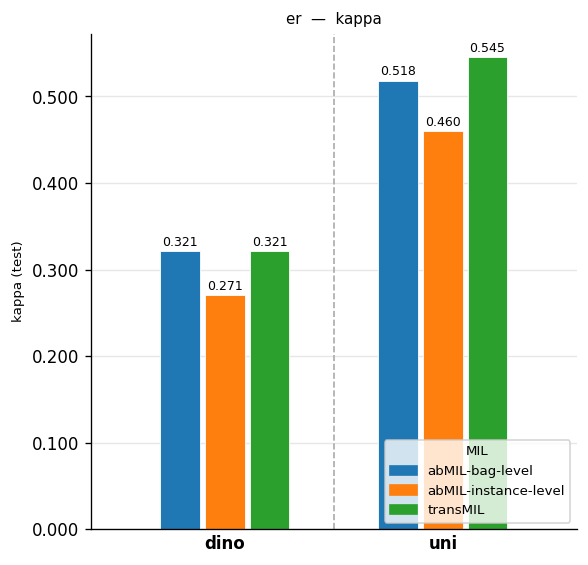

,freeze,lr,wd,batch_size,optimizer,weighted_loss,ductal,► balanced_accuracy (test),accuracy,balanced_accuracy,f1_macro,f1_weighted,auroc,auprc_macro,auprc_weighted,mcc,kappa
1,frozen,0.0000,0.0001,32,AdamW,True,False,0.7324,0.7550,0.7324,0.7126,0.7630,0.8191,0.8053,0.8580,0.4350,0.4287
2,frozen,0.0000,0.0010,32,AdamW,True,False,0.7324,0.7550,0.7324,0.7126,0.7630,0.8191,0.8053,0.8580,0.4350,0.4287
3,frozen,0.0000,0.0005,32,AdamW,True,False,0.7324,0.7550,0.7324,0.7126,0.7630,0.8191,0.8053,0.8580,0.4350,0.4287


,freeze,lr,wd,batch_size,optimizer,weighted_loss,ductal,► balanced_accuracy (test),accuracy,balanced_accuracy,f1_macro,f1_weighted,auroc,auprc_macro,auprc_weighted,mcc,kappa
1,frozen,0.0000,0.0010,32,AdamW,True,False,0.6867,0.7219,0.6867,0.6717,0.7303,0.8029,0.7861,0.8450,0.3511,0.3469
2,frozen,0.0000,0.0001,32,AdamW,True,False,0.6867,0.7219,0.6867,0.6717,0.7303,0.8029,0.7861,0.8450,0.3511,0.3469
3,frozen,0.0000,0.0005,32,AdamW,True,False,0.6867,0.7219,0.6867,0.6717,0.7303,0.8029,0.7861,0.8450,0.3511,0.3469


,freeze,lr,wd,batch_size,optimizer,weighted_loss,ductal,► balanced_accuracy (test),accuracy,balanced_accuracy,f1_macro,f1_weighted,auroc,auprc_macro,auprc_weighted,mcc,kappa
1,frozen,0.0000,0.0001,32,AdamW,True,False,0.7231,0.7748,0.7231,0.7196,0.7765,0.7998,0.7783,0.8377,0.4396,0.4394
2,frozen,0.0000,0.0005,32,AdamW,True,False,0.7231,0.7748,0.7231,0.7196,0.7765,0.7998,0.7783,0.8377,0.4396,0.4394
3,frozen,0.0000,0.0001,32,AdamW,True,False,0.7200,0.7815,0.7200,0.7216,0.7806,0.8033,0.7789,0.8399,0.4434,0.4433



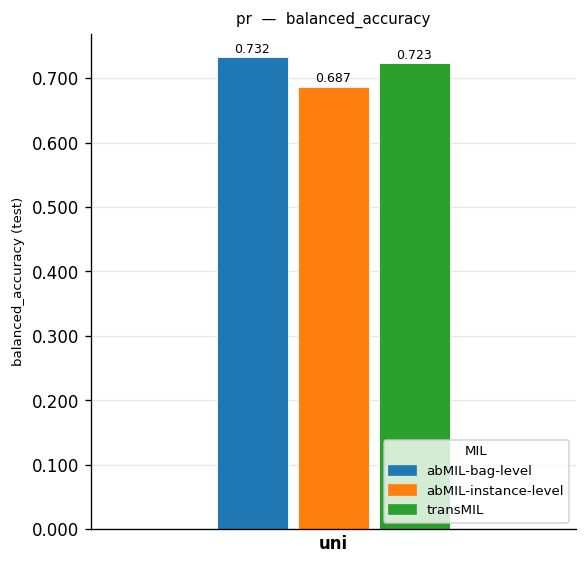
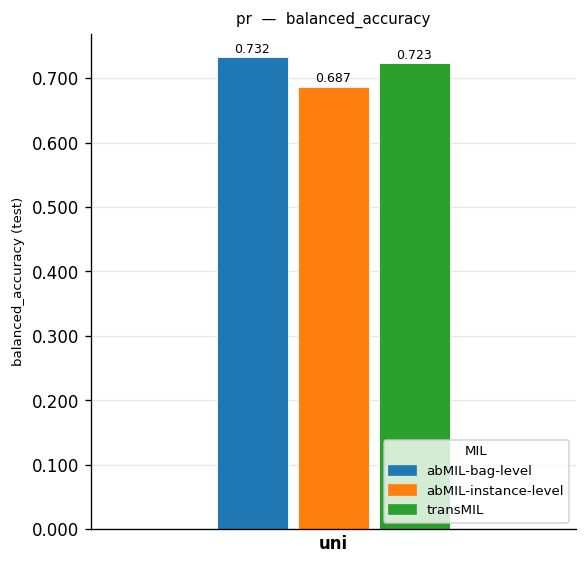
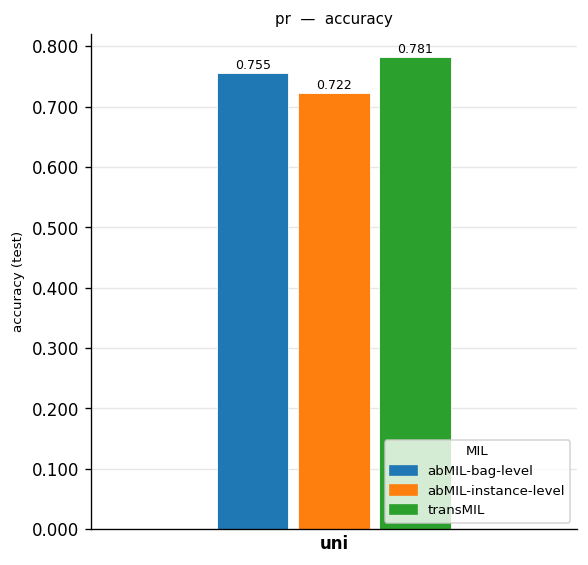
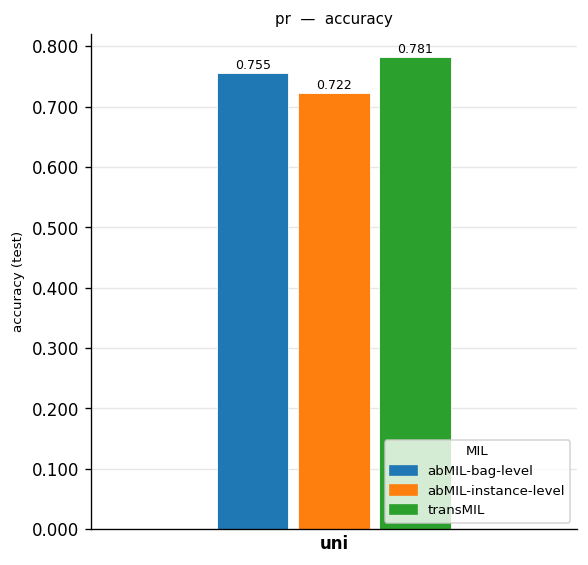
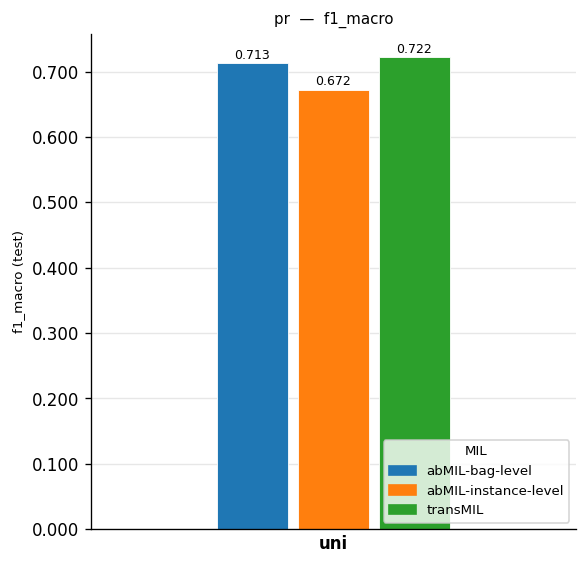
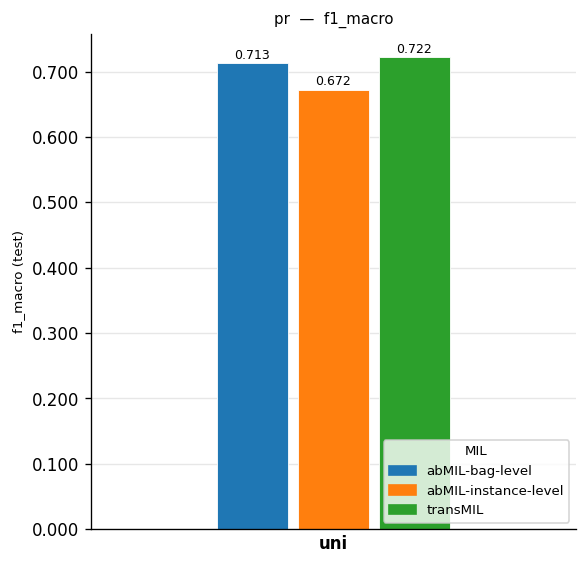


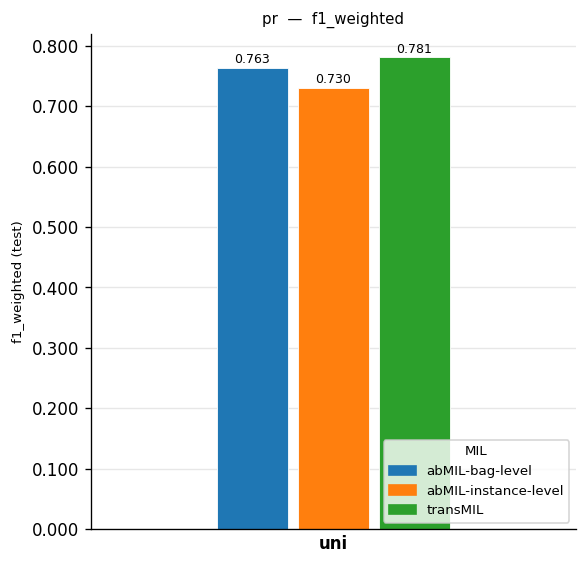
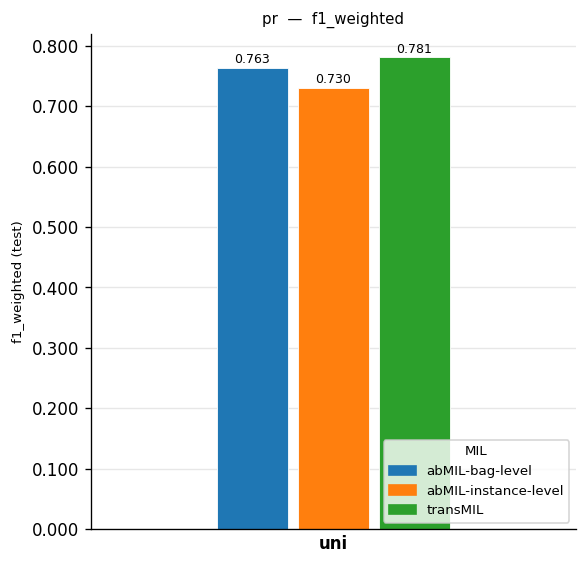
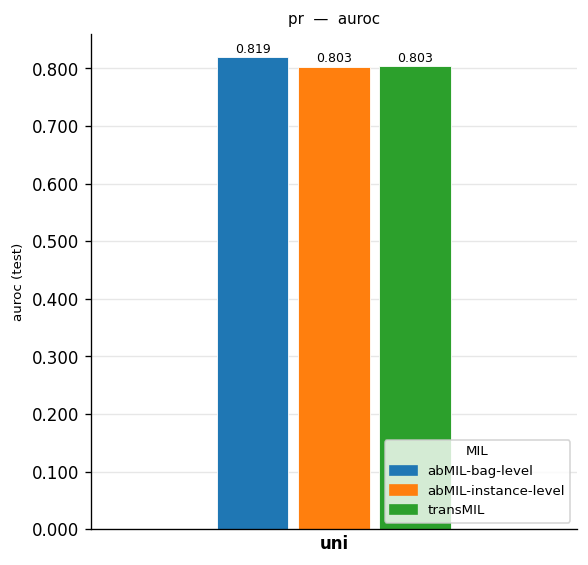
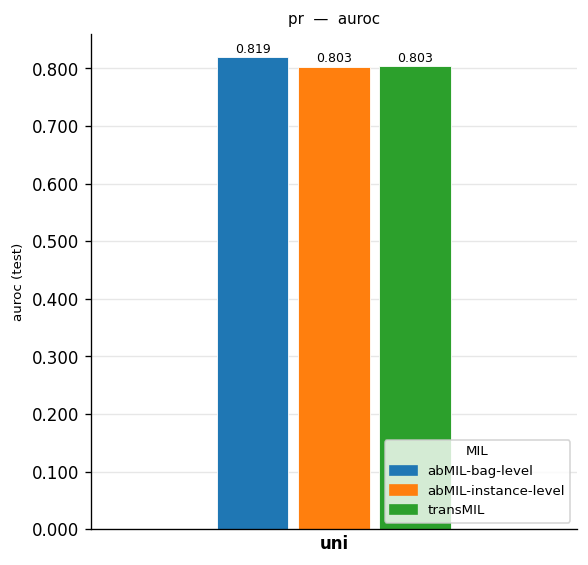
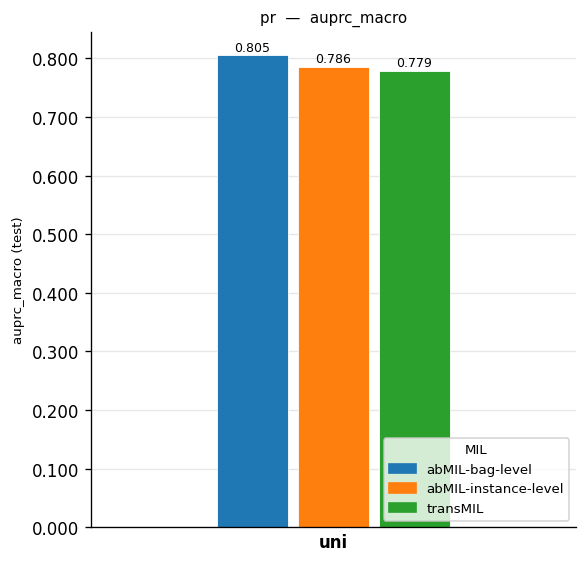
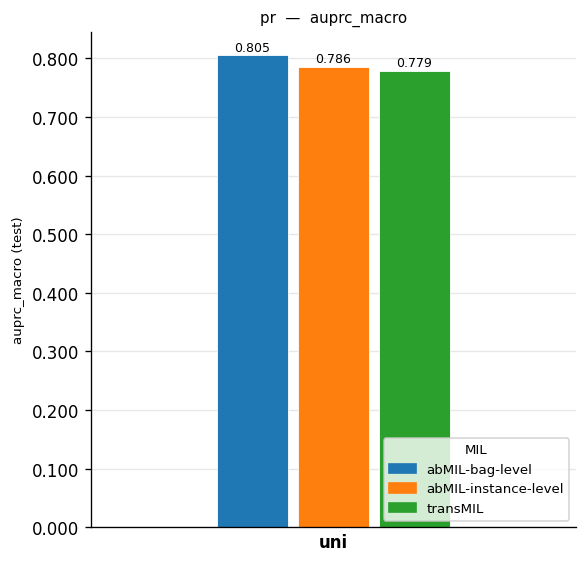


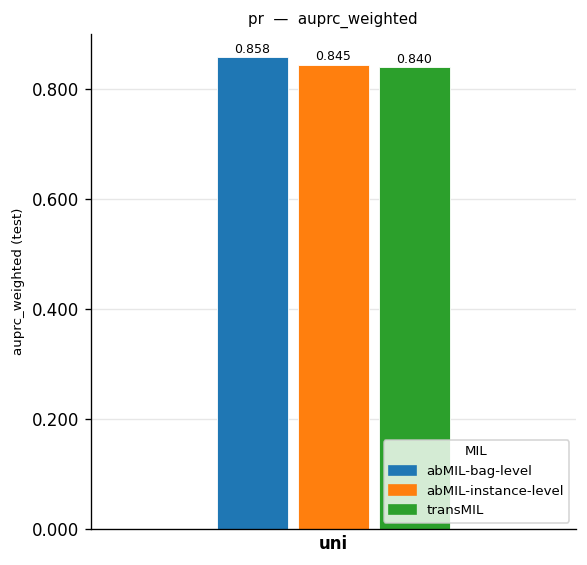
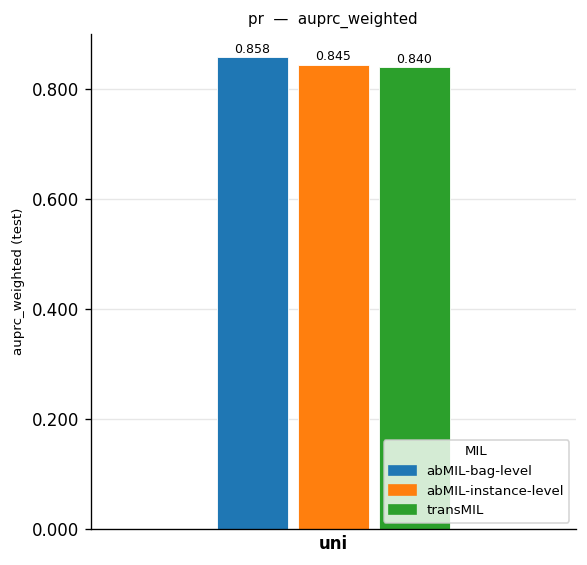
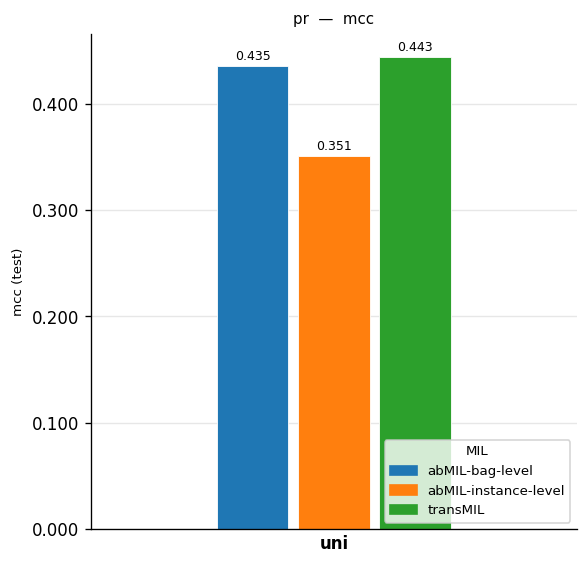
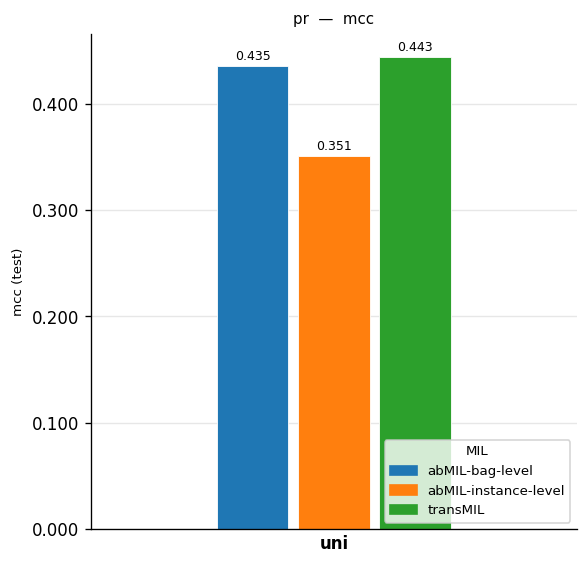
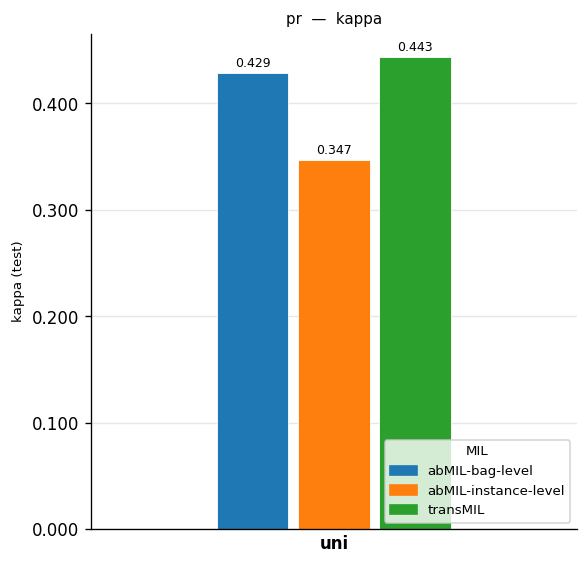
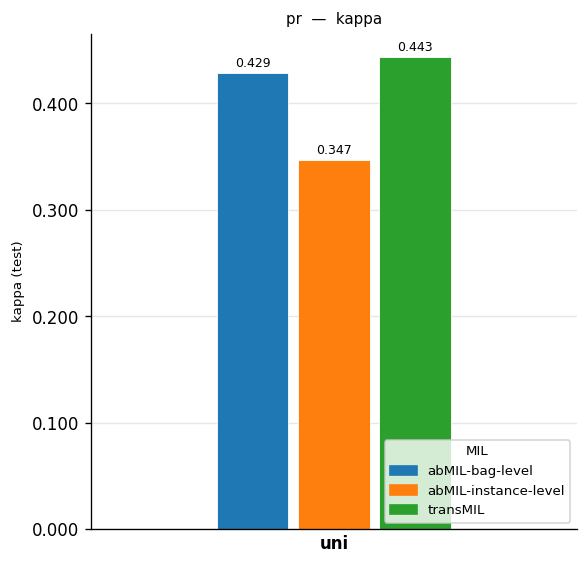

In [57]:
# ─────────────────────────────────────────────────────────────────────────────
# RANKING POR TAREA → encoder × MIL  +  barplot por tarea
# ─────────────────────────────────────────────────────────────────────────────
if all_runs.empty:
    print('⚠️  No se encontraron experimentos válidos. Revisa RESULTS_PATH y RANK_METRIC.')
else:
    display(HTML(
        f'<h2>Ranking — <code>{RANK_METRIC}</code> ({RANK_SPLIT})'
        f' | Top {TOP_N} por tarea × encoder × MIL</h2>'
    ))

    for task in sorted(all_runs['task'].unique()):
        task_df = all_runs[all_runs['task'] == task]

        display(HTML(
            f"<h2 style='margin-top:40px; border-bottom:2px solid #555; padding-bottom:6px'>"
            f"📋 Tarea: {task} "
            f"<span style='font-size:0.7em; font-weight:normal; color:#666'>({len(task_df)} experimentos)</span></h2>"
        ))

        for (model, mil), grp in task_df.groupby(['model', 'mil'], sort=True):
            show_group_table(grp, f'🧪 encoder={model} | MIL={mil}  ({len(grp)} runs)', TOP_N)

        display(HTML(f"<h4 style='margin-top:28px'>📊 Comparativa visual — tarea: {task}</h4>"))
        barplot_task(task_df, task)


In [58]:
# ─────────────────────────────────────────────────────────────────────────────
# RANKING GLOBAL POR TAREA
# Para cada tarea: top N experimentos de cualquier combinación encoder × freeze × MIL,
# sin restricción de hiperparámetros (todos los runs de esa tarea)
# ─────────────────────────────────────────────────────────────────────────────
if not all_runs.empty:
    display(HTML(f'<h2>🏆 Ranking global por tarea — {RANK_METRIC} ({RANK_SPLIT})</h2>'))

    metric_cols = [c for c in DISPLAY_METRICS if c in all_runs.columns]
    id_cols = ['model', 'mil', 'freeze', 'lr', 'wd', 'optimizer', 'weighted_loss']

    for task in sorted(all_runs['task'].unique()):
        task_df = all_runs[all_runs['task'] == task].head(TOP_N_GLOBAL).copy()
        task_df.index = range(1, len(task_df) + 1)

        cols = [c for c in id_cols + metric_cols if c in task_df.columns]
        task_df_disp = task_df[cols].rename(columns={'rank_value': f'► {RANK_METRIC} ({RANK_SPLIT})'})

        display(HTML(
            f"<h3 style='margin-top:32px; border-bottom:1px solid #888; padding-bottom:4px'>"
            f"📋 Tarea: {task} "
            f"<span style='font-size:0.75em; font-weight:normal; color:#666'>"
            f"(top {len(task_df)} de {len(all_runs[all_runs['task']==task])} experimentos)</span></h3>"
        ))
        display(task_df_disp.style.format(precision=4, na_rep='—'))


,model,mil,freeze,lr,wd,optimizer,weighted_loss,► balanced_accuracy (test),accuracy,balanced_accuracy,f1_macro,f1_weighted,auroc,auprc_macro,auprc_weighted,mcc,kappa
1,uni,abMIL-bag-level,frozen,0.0000,0.0001,AdamW,True,0.7930,0.7947,0.7930,0.7562,0.8043,0.8661,0.8375,0.8929,0.5328,0.5181
2,uni,abMIL-bag-level,frozen,0.0000,0.0005,AdamW,True,0.7930,0.7947,0.7930,0.7562,0.8043,0.8661,0.8375,0.8929,0.5328,0.5181
3,uni,abMIL-bag-level,frozen,0.0000,0.0001,AdamW,True,0.7930,0.7947,0.7930,0.7562,0.8043,0.8638,0.8375,0.8919,0.5328,0.5181
4,uni,abMIL-bag-level,frozen,0.0000,0.0010,AdamW,True,0.7930,0.7947,0.7930,0.7562,0.8043,0.8661,0.8375,0.8929,0.5328,0.5181
5,uni,abMIL-bag-level,frozen,0.0000,0.0005,AdamW,True,0.7930,0.7947,0.7930,0.7562,0.8043,0.8638,0.8375,0.8919,0.5328,0.5181
6,uni,abMIL-bag-level,frozen,0.0000,0.0010,AdamW,True,0.7930,0.7947,0.7930,0.7562,0.8043,0.8638,0.8375,0.8919,0.5328,0.5181
7,uni,abMIL-bag-level,frozen,0.0000,0.0010,AdamW,True,0.7930,0.7947,0.7930,0.7562,0.8043,0.8635,0.8312,0.8896,0.5328,0.5181
8,uni,abMIL-bag-level,frozen,0.0000,0.0001,AdamW,True,0.7930,0.7947,0.7930,0.7562,0.8043,0.8635,0.8312,0.8896,0.5328,0.5181
9,uni,abMIL-bag-level,frozen,0.0000,0.0005,AdamW,True,0.7930,0.7947,0.7930,0.7562,0.8043,0.8635,0.8312,0.8896,0.5328,0.5181
10,uni,transMIL,frozen,0.0000,0.0005,AdamW,True,0.7845,0.8212,0.7845,0.7722,0.8247,0.8763,0.8440,0.8983,0.5471,0.5451


,model,mil,freeze,lr,wd,optimizer,weighted_loss,► balanced_accuracy (test),accuracy,balanced_accuracy,f1_macro,f1_weighted,auroc,auprc_macro,auprc_weighted,mcc,kappa
1,uni,abMIL-bag-level,frozen,0.0000,0.0001,AdamW,True,0.7324,0.7550,0.7324,0.7126,0.7630,0.8191,0.8053,0.8580,0.4350,0.4287
2,uni,abMIL-bag-level,frozen,0.0000,0.0010,AdamW,True,0.7324,0.7550,0.7324,0.7126,0.7630,0.8191,0.8053,0.8580,0.4350,0.4287
3,uni,abMIL-bag-level,frozen,0.0000,0.0005,AdamW,True,0.7324,0.7550,0.7324,0.7126,0.7630,0.8191,0.8053,0.8580,0.4350,0.4287
4,uni,abMIL-bag-level,frozen,0.0000,0.0001,AdamW,True,0.7278,0.7483,0.7278,0.7065,0.7571,0.8144,0.7953,0.8519,0.4246,0.4173
5,uni,abMIL-bag-level,frozen,0.0000,0.0005,AdamW,True,0.7278,0.7483,0.7278,0.7065,0.7571,0.8144,0.7953,0.8519,0.4246,0.4173
6,uni,abMIL-bag-level,frozen,0.0000,0.0001,AdamW,True,0.7278,0.7483,0.7278,0.7065,0.7571,0.8171,0.7942,0.8521,0.4246,0.4173
7,uni,abMIL-bag-level,frozen,0.0000,0.0010,AdamW,True,0.7278,0.7483,0.7278,0.7065,0.7571,0.8144,0.7953,0.8519,0.4246,0.4173
8,uni,abMIL-bag-level,frozen,0.0000,0.0005,AdamW,True,0.7278,0.7483,0.7278,0.7065,0.7571,0.8171,0.7942,0.8521,0.4246,0.4173
9,uni,abMIL-bag-level,frozen,0.0000,0.0010,AdamW,True,0.7278,0.7483,0.7278,0.7065,0.7571,0.8171,0.7942,0.8521,0.4246,0.4173
10,uni,transMIL,frozen,0.0000,0.0001,AdamW,True,0.7231,0.7748,0.7231,0.7196,0.7765,0.7998,0.7783,0.8377,0.4396,0.4394


Inspeccionando: 20260422_200803_task-er_weighted_loss_model-uni_frozen_MIL-abMIL-bag-level_AdamW_lr5e-06_wd0.0001_bs32_ep150


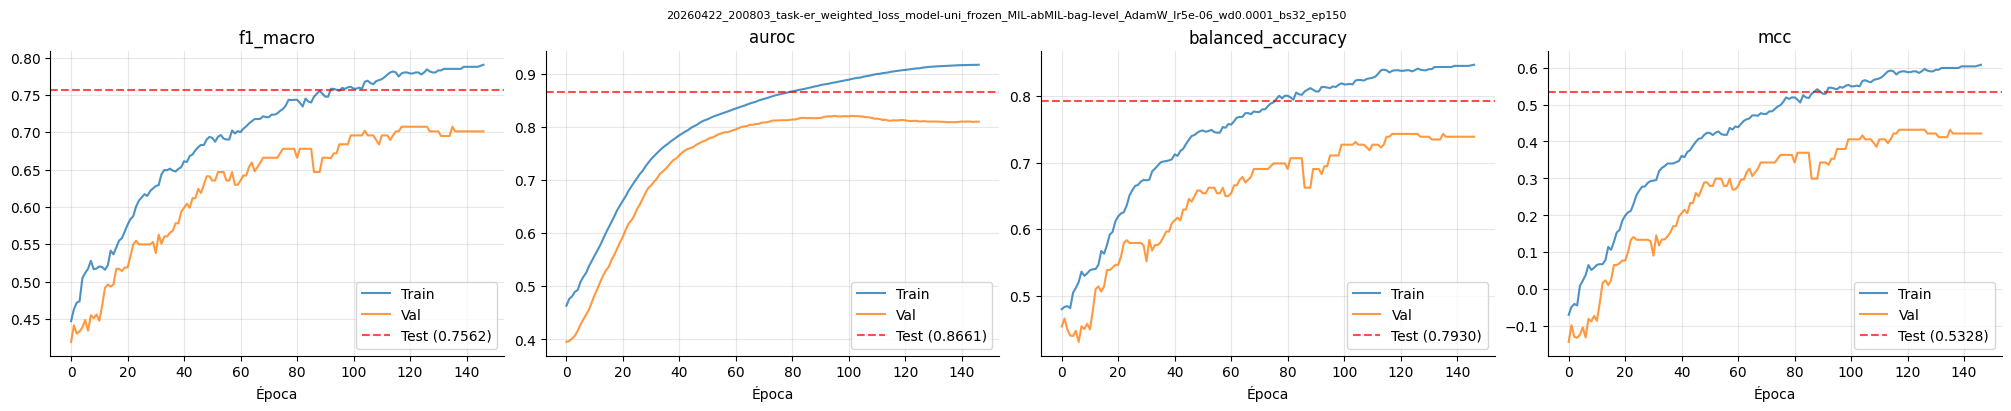


── Métricas de test ──


,epoch,task,accuracy,balanced_accuracy,precision_pos,recall_pos,f1_pos,precision_neg,recall_neg,f1_neg,...,precision_weighted,recall_weighted,f1_weighted,kappa,mcc,auroc,auprc_pos,auprc_neg,auprc_macro,auprc_weighted
0,0,er,0.7947,0.7930,0.9184,0.7965,0.8531,0.5660,0.7895,0.6593,...,0.8297,0.7947,0.8043,0.5181,0.5328,0.8661,0.9491,0.1510,0.8375,0.8929


In [59]:
# ─────────────────────────────────────────────────────────────────────────────
# INSPECCIÓN DE UN EXPERIMENTO CONCRETO
# Curvas train/val por época + línea de test para el #1 del ranking o el indicado
# ─────────────────────────────────────────────────────────────────────────────
INSPECT_RUN  = None   # run_name exacto, o None → usa el #1 del ranking global
PLOT_METRICS = ['f1_macro', 'auroc', 'balanced_accuracy', 'mcc']

if not all_runs.empty:
    if INSPECT_RUN is None:
        INSPECT_RUN = all_runs.iloc[0]['run_name']

    run_dir = os.path.join(RESULTS_PATH, INSPECT_RUN)
    print(f'Inspeccionando: {INSPECT_RUN}')

    train_df = load_csv(run_dir, 'train')
    val_df   = load_csv(run_dir, 'val')
    test_df  = load_csv(run_dir, 'test')

    available = [m for m in PLOT_METRICS
                 if (train_df is not None and m in train_df.columns)
                 or (val_df   is not None and m in val_df.columns)]

    if available:
        fig, axes = plt.subplots(1, len(available), figsize=(5 * len(available), 4),
                                 constrained_layout=True)
        if len(available) == 1:
            axes = [axes]
        for ax, metric in zip(axes, available):
            if train_df is not None and metric in train_df.columns:
                ax.plot(train_df['epoch'], train_df[metric], label='Train', alpha=0.8)
            if val_df is not None and metric in val_df.columns:
                ax.plot(val_df['epoch'], val_df[metric], label='Val', alpha=0.8)
            if test_df is not None and metric in test_df.columns:
                tv = test_df[metric].iloc[0]
                ax.axhline(tv, linestyle='--', color='red', alpha=0.7, label=f'Test ({tv:.4f})')
            ax.set_title(metric); ax.set_xlabel('Época'); ax.legend()
            ax.grid(alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
        fig.suptitle(INSPECT_RUN, fontsize=8, wrap=True)
        plt.show()
    else:
        print(f'Ninguna métrica de {PLOT_METRICS} encontrada.')

    if test_df is not None:
        print('\n── Métricas de test ──')
        display(test_df)
